# Diabetes Classification: Traditional ML vs Deep Learning
**Author:** Isimbi Nelly Assoumpta

**Summative Assignment:** Model Training and Evaluation

**Links:** GitHub: (add link) | Google Drive: (add link) | Video: (add link)

In this project I tried to predict whether a person has diabetes using survey answers about their health and lifestyle. I used the CDC Diabetes Health Indicators dataset (BRFSS 2015, downloaded from Kaggle), which has 253,680 rows and 21 features.

I compared two approaches: traditional machine learning (scikit-learn) and deep learning (TensorFlow/Keras with tf.data). I run 9 experiments, log them with Weights & Biases in offline mode, and evaluate the best models on a held-out test set.

## 1. Setup and loading the data
First I install wandb, then import libraries, set the random seed (42) so my results can be repeated, and set W&B to offline mode. I also mount my Google Drive and read the CSV directly from the zip file, so the raw data is never committed to GitHub.

I used the **binary** file (`diabetes_binary_health_indicators_BRFSS2015.csv`). The zip also has a 3-class version and a 50/50 balanced version. I avoided the balanced one because it hides the real class imbalance, which is one of the main challenges here.

Note: `ZIP_PATH` in the next cell points to my Drive folder and needs to be changed if someone else runs this.

In [1]:
!pip install -q wandb

In [2]:
import os, random, zipfile
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Weights & Biases in offline mode: logs saved locally, no login needed
os.environ["WANDB_MODE"] = "offline"
os.environ["WANDB_DIR"] = "./wandb_logs"
os.makedirs("./wandb_logs", exist_ok=True)

# Connect Colab to your Google Drive (a pop-up will ask for permission)
from google.colab import drive
drive.mount("/content/drive")

# CHANGE THIS if your zip has a different name or sits somewhere else
ZIP_PATH = "/content/drive/MyDrive/Summative_Diabetes_Project/archive (1).zip"
CSV_NAME = "diabetes_binary_health_indicators_BRFSS2015.csv"

with zipfile.ZipFile(ZIP_PATH) as z:
    print("Files inside the zip:", z.namelist())
    with z.open(CSV_NAME) as f:
        df = pd.read_csv(f)

TARGET = "Diabetes_binary"
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

print("Features shape:", X.shape)
print("Target distribution:\n", y.value_counts())
print("Share of positive class:", round(y.mean(), 3))

Mounted at /content/drive
Files inside the zip: ['diabetes_012_health_indicators_BRFSS2015.csv', 'diabetes_binary_5050split_health_indicators_BRFSS2015.csv', 'diabetes_binary_health_indicators_BRFSS2015.csv']
Features shape: (253680, 21)
Target distribution:
 Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64
Share of positive class: 0.139


**What I see:** 253,680 rows and 21 features, with about 13.9% of people labelled as having diabetes. The data is imbalanced, so accuracy alone would be misleading: a model that always says "no diabetes" would already get around 86%. That's why I focus on recall, precision, PR-AUC and ROC-AUC.

## 2. Cleaning and splitting the data
Here I do four things, in this order:
1. **Remove duplicate rows before splitting**, so the same row can't end up in both train and test (that would leak information and inflate the scores).
2. **Split 70/15/15** into train, validation and test, stratified so each part keeps the same share of diabetes cases. I compare experiments on the validation set and only touch the test set at the end.
3. **Clip BMI** at the 1st and 99th percentiles of the training set. These extreme values are real people, so I limit their influence instead of deleting rows.
4. **Standardize the features**, fitting the scaler on training data only to avoid leakage.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Remove duplicate rows BEFORE splitting (prevents train/test leakage)
rows_before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {rows_before} | after removing duplicates: {len(df_clean)}")

X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET].astype(int)
print("Positive rate after cleaning:", round(y.mean(), 3))

# 2. Stratified split: 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# 3. Clip BMI using limits learned from TRAIN only
bmi_low, bmi_high = X_train["BMI"].quantile([0.01, 0.99])
print(f"BMI clip limits: {bmi_low:.1f} to {bmi_high:.1f}")
for part in (X_train, X_val, X_test):
    part["BMI"] = part["BMI"].clip(bmi_low, bmi_high)

# 4. Scale features (scaler learns from TRAIN only)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Positive rate -> train:", round(y_train.mean(), 3),
      "val:", round(y_val.mean(), 3), "test:", round(y_test.mean(), 3))

Rows before: 253680 | after removing duplicates: 229474
Positive rate after cleaning: 0.153
BMI clip limits: 18.0 to 50.0
Train: (160631, 21) | Val: (34421, 21) | Test: (34422, 21)
Positive rate -> train: 0.153 val: 0.153 test: 0.153


## 3. Exploring the data
This cell looks at the raw data (before cleaning) to decide what needs fixing: missing values, duplicates, BMI outliers and class balance. These findings are why Section 2 above does the cleaning it does.

Missing values per column:
 0 total missing

float64    22
Name: count, dtype: int64 

Duplicate rows: 24206 (9.5% of the data)

             BMI   MentHlth   PhysHlth    GenHlth        Age  Education  \
count  253680.00  253680.00  253680.00  253680.00  253680.00  253680.00   
mean       28.38       3.18       4.24       2.51       8.03       5.05   
std         6.61       7.41       8.72       1.07       3.05       0.99   
min        12.00       0.00       0.00       1.00       1.00       1.00   
25%        24.00       0.00       0.00       2.00       6.00       4.00   
50%        27.00       0.00       0.00       2.00       8.00       5.00   
75%        31.00       2.00       3.00       3.00      10.00       6.00   
max        98.00      30.00      30.00       5.00      13.00       6.00   

          Income  
count  253680.00  
mean        6.05  
std         2.07  
min         1.00  
25%         5.00  
50%         7.00  
75%         8.00  
max         8.00   

BMI above 41.5: 9820 r

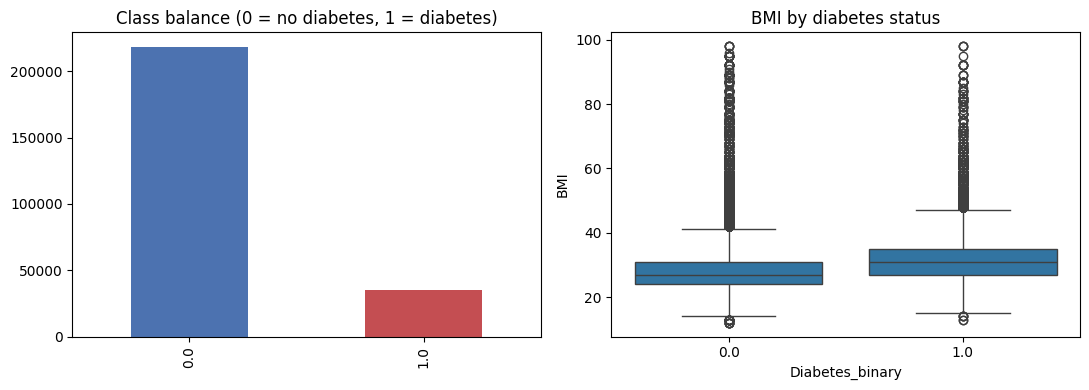

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Basic structure and missing values
print("Missing values per column:\n", df.isna().sum().sum(), "total missing\n")
print(df.dtypes.value_counts(), "\n")

# 2. Duplicate rows
n_dup = df.duplicated().sum()
print(f"Duplicate rows: {n_dup} ({n_dup / len(df):.1%} of the data)\n")

# 3. Numeric summary of the columns that are not simple yes/no
num_cols = ["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Education", "Income"]
print(df[num_cols].describe().round(2), "\n")

# 4. BMI outliers using the IQR rule
q1, q3 = df["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
n_out = (df["BMI"] > upper).sum()
print(f"BMI above {upper:.1f}: {n_out} rows ({n_out / len(df):.1%})")

# 5. Charts: class balance and BMI by diabetes status
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df[TARGET].value_counts().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Class balance (0 = no diabetes, 1 = diabetes)")
ax[0].set_xlabel("")
sns.boxplot(data=df, x=TARGET, y="BMI", ax=ax[1])
ax[1].set_title("BMI by diabetes status")
plt.tight_layout()
plt.show()

## 4. Helper function for tracking experiments
To keep the notebook clean and avoid repeating code, I wrote one function, `evaluate_and_log`. Every experiment calls it to compute accuracy, precision, recall, F1, ROC-AUC and PR-AUC, log the run to W&B (offline), and add a row to my `results` table. This is also what makes the experiment table traceable to real logged runs.

In [5]:
import time
import wandb
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)

WANDB_PROJECT = "diabetes-summative"
SPLIT_INFO = "70/15/15 stratified, seed 42, evaluated on validation"

# Keep existing results if this cell is re-run
if "results" not in globals():
    results = []

def evaluate_and_log(exp_id, name, approach, y_true, y_prob, params,
                     train_time, threshold=0.5, notes="", history=None):
    """Compute metrics, log the run to W&B (offline), and add a row to `results`.
    If `history` (a Keras history dict) is given, per-epoch curves are logged too."""
    y_pred = (y_prob >= threshold).astype(int)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
    }

    wandb.init(project=WANDB_PROJECT, name=f"{exp_id}_{name}",
               dir="./wandb_logs", mode="offline", reinit=True,
               config={**params, "approach": approach,
                       "threshold": threshold, "split": SPLIT_INFO})
    if history is not None:
        for epoch in range(len(history["loss"])):
            wandb.log({k: float(v[epoch]) for k, v in history.items()}, step=epoch)
    wandb.log({**metrics, "train_time_sec": train_time})
    wandb.finish()

    results.append({
        "exp": exp_id, "name": name, "approach": approach,
        "params": str(params), "threshold": threshold,
        **{k: round(v, 4) for k, v in metrics.items()},
        "train_time_sec": round(train_time, 1), "notes": notes,
    })
    cols = ["exp", "name", "accuracy", "precision", "recall",
            "f1", "roc_auc", "pr_auc", "train_time_sec"]
    return pd.DataFrame(results)[cols]

## 5. Traditional machine learning (Experiments 1 to 5)
### Experiments 1 and 2: Logistic Regression
E1 is my baseline: a plain Logistic Regression on the scaled features. E2 is the same model with `class_weight="balanced"`, to see what happens when the model is told to take the minority class more seriously.

In [6]:
from sklearn.linear_model import LogisticRegression

# ---- Experiment 1: Logistic Regression baseline ----
t0 = time.time()
lr1 = LogisticRegression(max_iter=1000, random_state=SEED)
lr1.fit(X_train_s, y_train)
t_lr1 = time.time() - t0
prob_lr1 = lr1.predict_proba(X_val_s)[:, 1]
evaluate_and_log("E1", "LogReg baseline", "Traditional ML", y_val, prob_lr1,
                 {"model": "LogisticRegression", "C": 1.0,
                  "class_weight": None, "max_iter": 1000}, t_lr1)

# ---- Experiment 2: Logistic Regression with class weights ----
t0 = time.time()
lr2 = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
lr2.fit(X_train_s, y_train)
t_lr2 = time.time() - t0
prob_lr2 = lr2.predict_proba(X_val_s)[:, 1]
table = evaluate_and_log("E2", "LogReg balanced", "Traditional ML", y_val, prob_lr2,
                         {"model": "LogisticRegression", "C": 1.0,
                          "class_weight": "balanced", "max_iter": 1000}, t_lr2)

display(table)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
train_time_sec,▁
accuracy,0.85323
f1,0.2627
pr_auc,0.43117
precision,0.56675


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
train_time_sec,▁
accuracy,0.71886
f1,0.45479
pr_auc,0.43021
precision,0.32327


,exp,name,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec
0,E1,LogReg baseline,0.8532,0.5668,0.1710,0.2627,0.8138,0.4312,0.7
1,E2,LogReg balanced,0.7189,0.3233,0.7667,0.4548,0.8141,0.4302,1.6


**What I found:** E1 has 85.3% accuracy, but recall is only 0.17, so it misses most people with diabetes. Its accuracy is barely above the 84.7% I'd get by always saying "no diabetes". E2 flips the trade-off: recall jumps to 0.77 but precision drops to 0.32. ROC-AUC (0.814) and PR-AUC (about 0.43) hardly changed, so class weights didn't improve the model's ranking of people. They only moved the decision line.

### Experiment 3: Random Forest
I use a Random Forest to check whether a non-linear model finds more signal than Logistic Regression. I capped it at 150 trees with max depth 14 so it trains fast, and I used balanced class weights. It doesn't need scaled data, so I used the unscaled features. I also print the feature importances to see what drives the predictions.

In [7]:
import os
os.environ["WANDB_SILENT"] = "true"   # quieter output
from sklearn.ensemble import RandomForestClassifier

# ---- Experiment 3: Random Forest ----
rf_params = {"model": "RandomForest", "n_estimators": 150, "max_depth": 14,
             "min_samples_leaf": 20, "class_weight": "balanced_subsample"}

t0 = time.time()
rf = RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=20,
                            class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
t_rf = time.time() - t0
prob_rf = rf.predict_proba(X_val)[:, 1]
table = evaluate_and_log("E3", "RandomForest", "Traditional ML", y_val, prob_rf,
                         rf_params, t_rf)
display(table)

# Which features matter most? (useful for feature engineering and your discussion)
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
print("\nTop 10 features:")
print(importances.sort_values(ascending=False).head(10).round(3))

accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
train_time_sec,▁
accuracy,0.73095
f1,0.46341
pr_auc,0.4429
precision,0.33339


,exp,name,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec
0,E1,LogReg baseline,0.8532,0.5668,0.1710,0.2627,0.8138,0.4312,0.7
1,E2,LogReg balanced,0.7189,0.3233,0.7667,0.4548,0.8141,0.4302,1.6
2,E3,RandomForest,0.7309,0.3334,0.7597,0.4634,0.8177,0.4429,48.3



Top 10 features:
HighBP                  0.213
GenHlth                 0.191
BMI                     0.142
Age                     0.114
HighChol                0.091
DiffWalk                0.048
PhysHlth                0.033
Income                  0.032
HeartDiseaseorAttack    0.027
MentHlth                0.020
dtype: float64


**What I found:** PR-AUC improved a little (0.4429 vs 0.4302) at about 48 seconds of training. The most important features are HighBP, GenHlth (self-rated health), BMI, Age and HighChol, which match the well-known diabetes risk factors. One caveat: Random Forest importances tend to favor continuous features like BMI, so I treat this ranking as a rough guide.

### Experiment 4: Gradient Boosting with hyperparameter tuning
I use scikit-learn's `HistGradientBoostingClassifier` because it's much faster than SVM or regular gradient boosting on 160k rows. I tune it with a random search (12 combinations, 3-fold cross-validation on the training set only) over learning rate, tree depth, leaf size and L2 regularization. The search is scored by PR-AUC because the classes are imbalanced.

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_depth": [3, 5, 7, None],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 0.1, 1.0, 5.0],
}

base_hgb = HistGradientBoostingClassifier(
    max_iter=300, early_stopping=True, validation_fraction=0.1,
    n_iter_no_change=15, class_weight="balanced", random_state=SEED)

search = RandomizedSearchCV(
    base_hgb, param_dist, n_iter=12, cv=3,
    scoring="average_precision",      # PR-AUC, fair for imbalanced data
    random_state=SEED, n_jobs=1, verbose=1)

t0 = time.time()
search.fit(X_train, y_train)
t_hgb = time.time() - t0

print("Best parameters:", search.best_params_)
print("Best CV PR-AUC:", round(search.best_score_, 4))

# Show every configuration tried (useful for the report's parameter-range column)
cv_table = (pd.DataFrame(search.cv_results_)
            [["param_learning_rate", "param_max_depth", "param_max_leaf_nodes",
              "param_min_samples_leaf", "param_l2_regularization",
              "mean_test_score"]]
            .sort_values("mean_test_score", ascending=False)
            .round(4))
display(cv_table)

# Evaluate the best model on the validation set
best_hgb = search.best_estimator_
prob_hgb = best_hgb.predict_proba(X_val)[:, 1]
table = evaluate_and_log("E4", "HistGB tuned", "Traditional ML", y_val, prob_hgb,
                         {"model": "HistGradientBoosting", **search.best_params_,
                          "search": "RandomizedSearchCV n_iter=12 cv=3",
                          "class_weight": "balanced"},
                         t_hgb)
display(table)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_depth': 5, 'learning_rate': 0.03, 'l2_regularization': 5.0}
Best CV PR-AUC: 0.4315


,param_learning_rate,param_max_depth,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,mean_test_score
11,0.03,5,63,20,5.0,0.4315
4,0.20,3,63,20,1.0,0.4314
6,0.20,3,63,50,0.1,0.4310
5,0.20,3,31,50,1.0,0.4309
8,0.10,5,15,50,0.0,0.4308
3,0.05,None,31,20,5.0,0.4307
10,0.05,3,15,100,5.0,0.4307
7,0.03,None,15,100,0.0,0.4306
2,0.05,7,31,50,1.0,0.4304
9,0.10,7,15,100,1.0,0.4301


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
train_time_sec,▁
accuracy,0.7091
f1,0.45513
pr_auc,0.44671
precision,0.31892


,exp,name,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec
0,E1,LogReg baseline,0.8532,0.5668,0.1710,0.2627,0.8138,0.4312,0.7
1,E2,LogReg balanced,0.7189,0.3233,0.7667,0.4548,0.8141,0.4302,1.6
2,E3,RandomForest,0.7309,0.3334,0.7597,0.4634,0.8177,0.4429,48.3
3,E4,HistGB tuned,0.7091,0.3189,0.7945,0.4551,0.8196,0.4467,190.5


**What I found:** All 12 configurations scored almost the same (cross-validated PR-AUC between 0.4293 and 0.4315). The best one is simple and heavily regularized: learning rate 0.03, depth 5, L2 of 5. Tuning barely mattered, which suggests the limit comes from the features and not the model settings. On validation this model reached PR-AUC 0.4467 and ROC-AUC 0.8196, my best classical result. Note that the 190 seconds includes the whole search (36 fits), not one training run.

### Experiment 5: Feature engineering
I create 8 new features from the existing columns: a count of risk conditions, BMI category, age x BMI, high blood pressure x high cholesterol, general health x age, total unhealthy days, a lifestyle score and a socioeconomic score. I train the same tuned model as E4 on them, so any change comes from the features alone. Because the differences might be tiny, I repeat the comparison with 3 random seeds.

In [9]:
def add_features(d):
    """Row-wise feature engineering (uses no information from other rows, so no leakage)."""
    d = d.copy()
    d["risk_count"] = (d["HighBP"] + d["HighChol"] + d["HeartDiseaseorAttack"]
                       + d["Stroke"] + d["DiffWalk"])
    d["bmi_category"] = pd.cut(d["BMI"], bins=[0, 18.5, 25, 30, 35, 40, 200],
                               labels=False, right=False)
    d["age_x_bmi"] = d["Age"] * d["BMI"]
    d["bp_x_chol"] = d["HighBP"] * d["HighChol"]
    d["genhlth_x_age"] = d["GenHlth"] * d["Age"]
    d["unhealthy_days"] = d["MentHlth"] + d["PhysHlth"]
    d["lifestyle_score"] = (d["PhysActivity"] + d["Fruits"] + d["Veggies"]
                            - d["Smoker"] - d["HvyAlcoholConsump"])
    d["ses_score"] = d["Education"] + d["Income"]
    return d

X_train_fe = add_features(X_train)
X_val_fe = add_features(X_val)
X_test_fe = add_features(X_test)
print("Features before:", X_train.shape[1], "| after:", X_train_fe.shape[1])

def fit_hgb(X_tr, X_ev, seed):
    """Train HistGradientBoosting with the best E4 settings; return model and probabilities."""
    m = HistGradientBoostingClassifier(
        max_iter=300, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=15, class_weight="balanced",
        random_state=seed, **search.best_params_)
    m.fit(X_tr, y_train)
    return m, m.predict_proba(X_ev)[:, 1]

# ---- Experiment 5: best classical model + engineered features ----
t0 = time.time()
hgb_fe, prob_hgb_fe = fit_hgb(X_train_fe, X_val_fe, SEED)
t_fe = time.time() - t0

table = evaluate_and_log("E5", "HistGB + engineered features", "Traditional ML",
                         y_val, prob_hgb_fe,
                         {"model": "HistGradientBoosting", **search.best_params_,
                          "features": "21 original + 8 engineered",
                          "class_weight": "balanced"},
                         t_fe,
                         notes="Same settings as E4; only the feature set changed")
display(table)

# ---- Noise check: same comparison with 3 different seeds ----
rows = []
for s in [42, 1, 2]:
    _, p_base = fit_hgb(X_train, X_val, s)
    _, p_fe = fit_hgb(X_train_fe, X_val_fe, s)
    rows.append({"seed": s,
                 "PR-AUC original": round(average_precision_score(y_val, p_base), 4),
                 "PR-AUC engineered": round(average_precision_score(y_val, p_fe), 4),
                 "ROC-AUC original": round(roc_auc_score(y_val, p_base), 4),
                 "ROC-AUC engineered": round(roc_auc_score(y_val, p_fe), 4)})
seed_table = pd.DataFrame(rows)
display(seed_table)
print("Mean PR-AUC  original:", round(seed_table["PR-AUC original"].mean(), 4),
      "| engineered:", round(seed_table["PR-AUC engineered"].mean(), 4))

Features before: 21 | after: 29


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
train_time_sec,▁
accuracy,0.70983
f1,0.45504
pr_auc,0.44596
precision,0.3192


,exp,name,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec
0,E1,LogReg baseline,0.8532,0.5668,0.1710,0.2627,0.8138,0.4312,0.7
1,E2,LogReg balanced,0.7189,0.3233,0.7667,0.4548,0.8141,0.4302,1.6
2,E3,RandomForest,0.7309,0.3334,0.7597,0.4634,0.8177,0.4429,48.3
3,E4,HistGB tuned,0.7091,0.3189,0.7945,0.4551,0.8196,0.4467,190.5
4,E5,HistGB + engineered features,0.7098,0.3192,0.7922,0.4550,0.8200,0.4460,11.9


,seed,PR-AUC original,PR-AUC engineered,ROC-AUC original,ROC-AUC engineered
0,42,0.4467,0.4460,0.8196,0.8200
1,1,0.4473,0.4475,0.8195,0.8198
2,2,0.4462,0.4456,0.8195,0.8193


Mean PR-AUC  original: 0.4467 | engineered: 0.4464


**What I found:** Engineered features did not help the gradient boosting model. Mean PR-AUC over 3 seeds was 0.4467 with the original features and 0.4464 with the engineered ones, and the difference changes sign between seeds, so it is noise. My explanation is that tree models already build interactions on their own through their splits.

### Saving a checkpoint
This cell saves my experiment table and W&B logs to Google Drive. I run it after each experiment so a disconnect doesn't make me lose results.

In [10]:
import shutil

CHECKPOINT_DIR = "/content/drive/MyDrive/Summative_Diabetes_Project/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

pd.DataFrame(results).to_csv(f"{CHECKPOINT_DIR}/experiment_results.csv", index=False)
shutil.copytree("./wandb_logs", f"{CHECKPOINT_DIR}/wandb_logs", dirs_exist_ok=True)
print("Saved", len(results), "experiments and W&B logs to Drive.")

Saved 5 experiments and W&B logs to Drive.


## 6. Deep learning (Experiments 6 to 8b)
### Experiment 6: Baseline neural network
I build a small Sequential MLP (64 and 32 units, ReLU, sigmoid output) on the scaled features. The data goes through a `tf.data` pipeline (shuffle, batch of 1024, prefetch). I use Adam with learning rate 0.001 and early stopping on validation loss. The helper functions here also draw the learning curves.

Epoch 1/40
157/157 - 3s - 20ms/step - loss: 0.3740 - pr_auc: 0.3304 - roc_auc: 0.7546 - val_loss: 0.3399 - val_pr_auc: 0.4297 - val_roc_auc: 0.8136
Epoch 2/40
157/157 - 1s - 8ms/step - loss: 0.3429 - pr_auc: 0.4182 - roc_auc: 0.8090 - val_loss: 0.3385 - val_pr_auc: 0.4359 - val_roc_auc: 0.8164
Epoch 3/40
157/157 - 1s - 8ms/step - loss: 0.3412 - pr_auc: 0.4244 - roc_auc: 0.8116 - val_loss: 0.3369 - val_pr_auc: 0.4417 - val_roc_auc: 0.8182
Epoch 4/40
157/157 - 1s - 8ms/step - loss: 0.3401 - pr_auc: 0.4285 - roc_auc: 0.8133 - val_loss: 0.3367 - val_pr_auc: 0.4422 - val_roc_auc: 0.8185
Epoch 5/40
157/157 - 2s - 10ms/step - loss: 0.3394 - pr_auc: 0.4313 - roc_auc: 0.8142 - val_loss: 0.3361 - val_pr_auc: 0.4438 - val_roc_auc: 0.8192
Epoch 6/40
157/157 - 2s - 15ms/step - loss: 0.3390 - pr_auc: 0.4329 - roc_auc: 0.8149 - val_loss: 0.3367 - val_pr_auc: 0.4417 - val_roc_auc: 0.8187
Epoch 7/40
157/157 - 2s - 15ms/step - loss: 0.3385 - pr_auc: 0.4350 - roc_auc: 0.8156 - val_loss: 0.3366 - val_pr_a

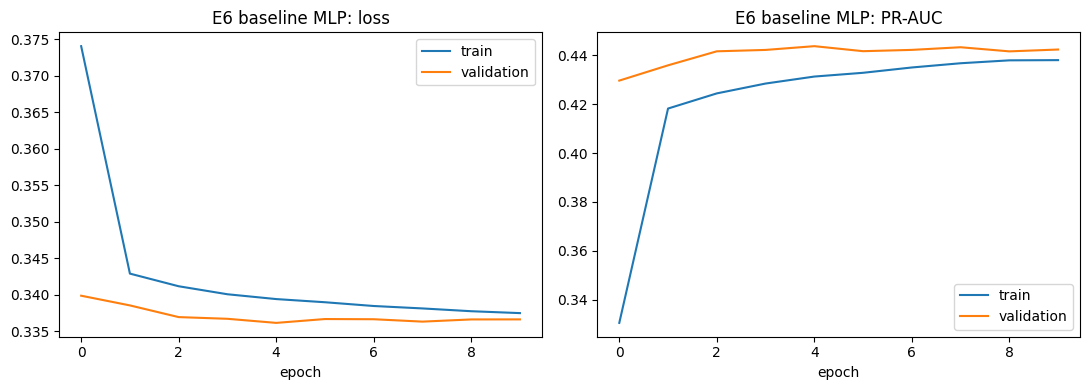

accuracy,▁
f1,▁
loss,█▂▂▁▁▁▁▁▁▁
pr_auc,▁▆▇▇▇▇▇███
precision,▁
recall,▁
roc_auc,▁▇▇▇▇█████
train_time_sec,▁
val_loss,█▆▂▂▁▂▂▁▂▂
val_pr_auc,▁▄▇▇█▇▇█▇▇
+1,...


,exp,name,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec
0,E1,LogReg baseline,0.8532,0.5668,0.1710,0.2627,0.8138,0.4312,0.7
1,E2,LogReg balanced,0.7189,0.3233,0.7667,0.4548,0.8141,0.4302,1.6
2,E3,RandomForest,0.7309,0.3334,0.7597,0.4634,0.8177,0.4429,48.3
3,E4,HistGB tuned,0.7091,0.3189,0.7945,0.4551,0.8196,0.4467,190.5
4,E5,HistGB + engineered features,0.7098,0.3192,0.7922,0.4550,0.8200,0.4460,11.9
5,E6,MLP baseline,0.8550,0.5954,0.1619,0.2545,0.8192,0.4439,17.0


In [11]:
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

BATCH = 1024

def make_ds(X_arr, y_arr, training):
    """tf.data pipeline: tensors -> (shuffle) -> batch -> prefetch."""
    ds = tf.data.Dataset.from_tensor_slices(
        (np.asarray(X_arr, dtype="float32"), np.asarray(y_arr, dtype="float32")))
    if training:
        ds = ds.shuffle(buffer_size=20000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

def plot_curves(history, title):
    """Learning curves: loss and PR-AUC for train vs validation."""
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["loss"], label="train")
    ax[0].plot(h["val_loss"], label="validation")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["pr_auc"], label="train")
    ax[1].plot(h["val_pr_auc"], label="validation")
    ax[1].set_title(f"{title}: PR-AUC"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    plt.show()

def keras_metrics():
    return [keras.metrics.AUC(name="roc_auc"),
            keras.metrics.AUC(name="pr_auc", curve="PR")]

train_ds = make_ds(X_train_s, y_train, training=True)
val_ds = make_ds(X_val_s, y_val, training=False)

# ---- Experiment 6: baseline MLP (Sequential API) ----
keras.utils.set_random_seed(SEED)
mlp1 = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
mlp1.compile(optimizer=keras.optimizers.Adam(1e-3),
             loss="binary_crossentropy", metrics=keras_metrics())

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)

t0 = time.time()
hist1 = mlp1.fit(train_ds, validation_data=val_ds, epochs=40,
                 callbacks=[early_stop], verbose=2)
t_mlp1 = time.time() - t0

plot_curves(hist1, "E6 baseline MLP")

prob_mlp1 = mlp1.predict(val_ds, verbose=0).ravel()
table = evaluate_and_log("E6", "MLP baseline", "Deep Learning", y_val, prob_mlp1,
                         {"model": "Sequential MLP", "layers": "64-32-1",
                          "activation": "relu", "optimizer": "Adam", "lr": 1e-3,
                          "batch_size": BATCH, "epochs_run": len(hist1.history["loss"]),
                          "early_stopping": "val_loss, patience 5",
                          "class_weight": None, "features": "21 original, scaled"},
                         t_mlp1, history=hist1.history)
display(table)

**What I found:** Training and validation curves stay close together, so there's no overfitting. Early stopping restored the weights from epoch 5. PR-AUC is 0.4439, close to the classical models. Like E1, the model has high accuracy (85.5%) but low recall (0.16), because the loss rewards predicting "no diabetes" for most people.

### Experiment 7: Wider network with regularization and class weights
Since E6 missed most positives, I add class weights through the tf.data pipeline. I also make the network wider (128, 64, 32 units) with BatchNorm, Dropout (0.3) and L2 regularization, and I stop early on validation PR-AUC because the weighted loss isn't comparable with E6's loss. The validation data stays unweighted.

Class weights: {0: np.float64(0.59), 1: np.float64(3.27)}
Epoch 1/40
157/157 - 7s - 44ms/step - loss: 0.5901 - pr_auc: 0.3380 - roc_auc: 0.7681 - val_loss: 0.5249 - val_pr_auc: 0.4325 - val_roc_auc: 0.8144
Epoch 2/40
157/157 - 3s - 21ms/step - loss: 0.5545 - pr_auc: 0.3955 - roc_auc: 0.7998 - val_loss: 0.5337 - val_pr_auc: 0.4360 - val_roc_auc: 0.8168
Epoch 3/40
157/157 - 4s - 28ms/step - loss: 0.5477 - pr_auc: 0.4042 - roc_auc: 0.8051 - val_loss: 0.5549 - val_pr_auc: 0.4386 - val_roc_auc: 0.8179
Epoch 4/40
157/157 - 3s - 17ms/step - loss: 0.5450 - pr_auc: 0.4086 - roc_auc: 0.8068 - val_loss: 0.5466 - val_pr_auc: 0.4406 - val_roc_auc: 0.8185
Epoch 5/40
157/157 - 7s - 44ms/step - loss: 0.5432 - pr_auc: 0.4111 - roc_auc: 0.8076 - val_loss: 0.5372 - val_pr_auc: 0.4412 - val_roc_auc: 0.8188
Epoch 6/40
157/157 - 3s - 21ms/step - loss: 0.5402 - pr_auc: 0.4126 - roc_auc: 0.8099 - val_loss: 0.5308 - val_pr_auc: 0.4413 - val_roc_auc: 0.8189
Epoch 7/40
157/157 - 3s - 16ms/step - loss: 0.5390 - p

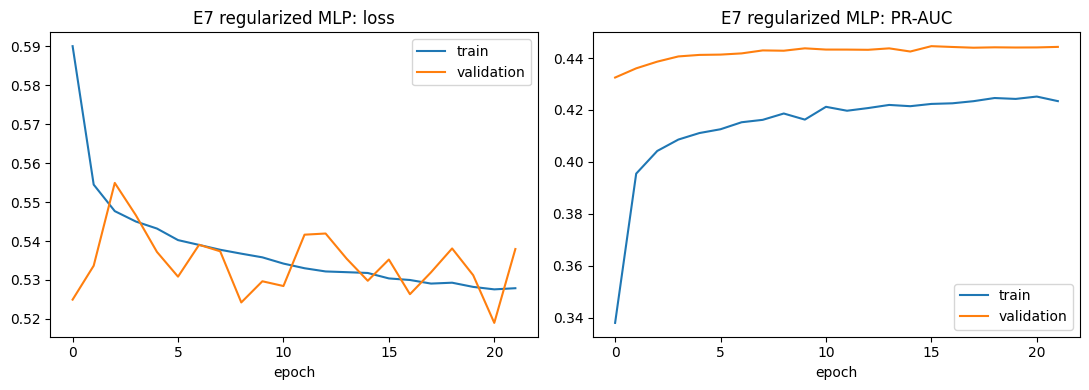

accuracy,▁
f1,▁
loss,█▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
pr_auc,▁▅▅▆▆▆▆▆▆▆▆▆▆▇▆▇▇▇▇▇▇█
precision,▁
recall,▁
roc_auc,▁▅▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇█
train_time_sec,▁
val_loss,▂▄█▆▅▃▅▅▂▃▃▅▅▄▃▄▂▄▅▃▁▅
val_pr_auc,▁▃▅▆▆▆▆▇▇█▇▇▇█▇███████
+1,...


,exp,name,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec
0,E1,LogReg baseline,0.8532,0.5668,0.1710,0.2627,0.8138,0.4312,0.7
1,E2,LogReg balanced,0.7189,0.3233,0.7667,0.4548,0.8141,0.4302,1.6
2,E3,RandomForest,0.7309,0.3334,0.7597,0.4634,0.8177,0.4429,48.3
3,E4,HistGB tuned,0.7091,0.3189,0.7945,0.4551,0.8196,0.4467,190.5
4,E5,HistGB + engineered features,0.7098,0.3192,0.7922,0.4550,0.8200,0.4460,11.9
5,E6,MLP baseline,0.8550,0.5954,0.1619,0.2545,0.8192,0.4439,17.0
6,E7,MLP wide + reg + class weights,0.6982,0.3127,0.8127,0.4516,0.8195,0.4447,77.8


In [12]:
# ---- Experiment 7: wider MLP + BatchNorm + Dropout + L2 + class weights ----
from tensorflow.keras import regularizers

pos_rate = y_train.mean()
CLASS_W = {0: 0.5 / (1 - pos_rate), 1: 0.5 / pos_rate}
print("Class weights:", {k: round(v, 2) for k, v in CLASS_W.items()})

def make_ds_weighted(X_arr, y_arr, class_w):
    """tf.data pipeline that adds a per-sample weight based on the class label."""
    X_arr = np.asarray(X_arr, dtype="float32")
    y_arr = np.asarray(y_arr, dtype="float32")
    w_arr = np.where(y_arr == 1, class_w[1], class_w[0]).astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr, w_arr))
    ds = ds.shuffle(buffer_size=20000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds_w = make_ds_weighted(X_train_s, y_train, CLASS_W)
val_ds = make_ds(X_val_s, y_val, training=False)   # validation stays unweighted

L2 = regularizers.l2(1e-4)
keras.utils.set_random_seed(SEED)
mlp2 = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(128, kernel_regularizer=L2),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(64, kernel_regularizer=L2),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu", kernel_regularizer=L2),
    layers.Dense(1, activation="sigmoid"),
])
mlp2.compile(optimizer=keras.optimizers.Adam(1e-3),
             loss="binary_crossentropy", metrics=keras_metrics())

early_stop2 = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True)

t0 = time.time()
hist2 = mlp2.fit(train_ds_w, validation_data=val_ds, epochs=40,
                 callbacks=[early_stop2], verbose=2)
t_mlp2 = time.time() - t0

plot_curves(hist2, "E7 regularized MLP")

prob_mlp2 = mlp2.predict(val_ds, verbose=0).ravel()
table = evaluate_and_log("E7", "MLP wide + reg + class weights", "Deep Learning",
                         y_val, prob_mlp2,
                         {"model": "Sequential MLP", "layers": "128-64-32-1",
                          "regularization": "BatchNorm, Dropout 0.3, L2 1e-4",
                          "optimizer": "Adam", "lr": 1e-3, "batch_size": BATCH,
                          "epochs_run": len(hist2.history["loss"]),
                          "early_stopping": "val_pr_auc, patience 6",
                          "class_weight": {k: round(v, 2) for k, v in CLASS_W.items()},
                          "features": "21 original, scaled"},
                         t_mlp2, history=hist2.history,
                         notes="Loss is class-weighted, so not comparable with E6 loss")
display(table)

**What I found:** Recall jumps to 0.81, but PR-AUC is almost the same as E6 (0.4447 vs 0.4439). So the class weights changed where the model draws its line, not how well it ranks people. In the loss chart, the training and validation losses aren't on the same scale because only the training loss is weighted, so I rely on the PR-AUC chart, where the two curves are close with no sign of overfitting.

### Experiments 8 and 8b: Functional API with a residual block
Here I use the Functional API to build a model with a skip connection, which the Sequential API can't express. I also add `ReduceLROnPlateau`, which halves the learning rate when validation PR-AUC stalls. E8 uses the 21 original features and E8b uses the 29 engineered features, so I can test whether feature engineering helps a neural network.

E8: 19 epochs, best val PR-AUC 0.4439, 75s


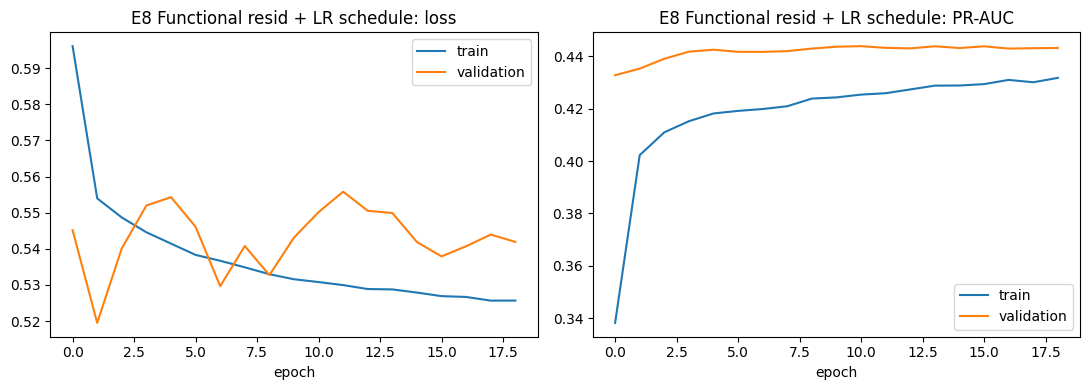

accuracy,▁
f1,▁
learning_rate,████████▄▄▄▄▄▄▂▂▂▁▁
loss,█▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁
pr_auc,▁▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇█
precision,▁
recall,▁
roc_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇██
train_time_sec,▁
val_loss,▆▁▅▇█▆▃▅▄▆▇█▇▇▅▅▅▆▅
+2,...


E8b: 24 epochs, best val PR-AUC 0.4456, 103s


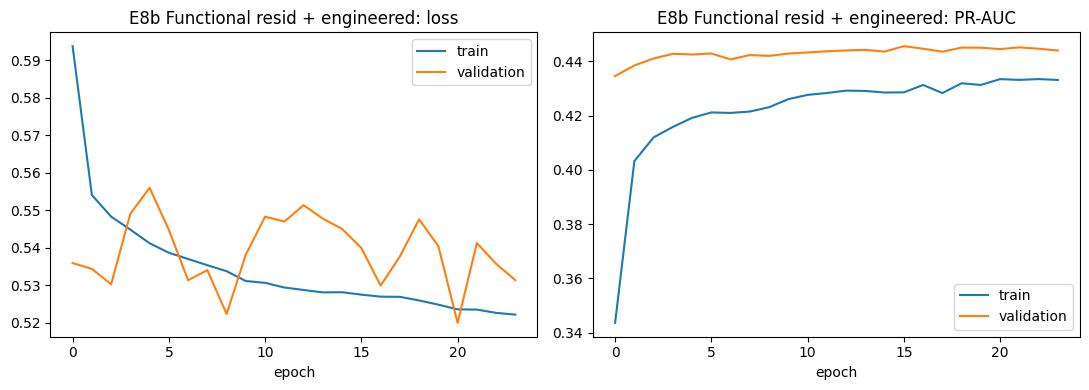

accuracy,▁
f1,▁
learning_rate,█████████▄▄▄▄▄▄▄▄▄▄▂▂▂▁▁
loss,█▄▄▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
pr_auc,▁▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇█
precision,▁
recall,▁
roc_auc,▁▅▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇█████
train_time_sec,▁
val_loss,▄▄▃▇█▆▃▄▁▅▇▆▇▆▆▅▃▄▆▅▁▅▄▃
+2,...


,exp,name,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec
0,E1,LogReg baseline,0.8532,0.5668,0.1710,0.2627,0.8138,0.4312,0.7
1,E2,LogReg balanced,0.7189,0.3233,0.7667,0.4548,0.8141,0.4302,1.6
2,E3,RandomForest,0.7309,0.3334,0.7597,0.4634,0.8177,0.4429,48.3
3,E4,HistGB tuned,0.7091,0.3189,0.7945,0.4551,0.8196,0.4467,190.5
4,E5,HistGB + engineered features,0.7098,0.3192,0.7922,0.4550,0.8200,0.4460,11.9
5,E6,MLP baseline,0.8550,0.5954,0.1619,0.2545,0.8192,0.4439,17.0
6,E7,MLP wide + reg + class weights,0.6982,0.3127,0.8127,0.4516,0.8195,0.4447,77.8
7,E8,Functional resid + LR schedule,0.7012,0.3145,0.8081,0.4527,0.8192,0.4443,75.5
8,E8b,Functional resid + engineered,0.7037,0.3159,0.8041,0.4536,0.8194,0.4460,103.2


In [13]:
# ---- Experiments 8 and 8b: Functional API + residual block + LR schedule ----

# Scale the engineered features (scaler learns from TRAIN only)
scaler_fe = StandardScaler().fit(X_train_fe)
X_train_fe_s = scaler_fe.transform(X_train_fe)
X_val_fe_s = scaler_fe.transform(X_val_fe)
X_test_fe_s = scaler_fe.transform(X_test_fe)

def build_functional(n_features, lr=2e-3):
    """Functional API model with one residual block (skip connection)."""
    inp = keras.Input(shape=(n_features,))
    x = layers.Dense(128, kernel_regularizer=L2)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.3)(x)

    h = layers.Dense(128, kernel_regularizer=L2)(x)     # residual branch
    h = layers.BatchNormalization()(h)
    h = layers.Activation("relu")(h)
    h = layers.Dropout(0.3)(h)
    x = layers.Add()([x, h])                             # skip connection

    x = layers.Dense(32, activation="relu", kernel_regularizer=L2)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="binary_crossentropy", metrics=keras_metrics())
    return model

def run_functional(exp_id, name, Xtr, Xv, feature_desc, notes):
    train_w = make_ds_weighted(Xtr, y_train, CLASS_W)
    val = make_ds(Xv, y_val, training=False)
    keras.utils.set_random_seed(SEED)
    model = build_functional(Xtr.shape[1])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max",
                                      patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max",
                                          factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(train_w, validation_data=val, epochs=40,
                     callbacks=callbacks, verbose=0)
    t = time.time() - t0
    n_ep = len(hist.history["loss"])
    best = max(hist.history["val_pr_auc"])
    print(f"{exp_id}: {n_ep} epochs, best val PR-AUC {best:.4f}, {t:.0f}s")

    plot_curves(hist, f"{exp_id} {name}")
    prob = model.predict(val, verbose=0).ravel()
    tbl = evaluate_and_log(
        exp_id, name, "Deep Learning", y_val, prob,
        {"model": "Functional API, residual block", "layers": "128 + res128 + 32",
         "regularization": "BatchNorm, Dropout 0.3, L2 1e-4",
         "optimizer": "Adam", "lr": "2e-3, ReduceLROnPlateau x0.5, patience 3",
         "batch_size": BATCH, "epochs_run": n_ep,
         "early_stopping": "val_pr_auc, patience 8",
         "class_weight": {k: round(v, 2) for k, v in CLASS_W.items()},
         "features": feature_desc},
        t, history=hist.history, notes=notes)
    return model, prob, tbl

model8, prob8, _ = run_functional(
    "E8", "Functional resid + LR schedule", X_train_s, X_val_s,
    "21 original, scaled", "Same features as E7; new architecture and LR schedule")

model8b, prob8b, table = run_functional(
    "E8b", "Functional resid + engineered", X_train_fe_s, X_val_fe_s,
    "21 original + 8 engineered, scaled", "Same as E8; only the feature set changed")

display(table)

**What I found:** E8 matches E7 (PR-AUC 0.4443 vs 0.4447), so the new architecture and learning-rate schedule didn't help. The learning rate did drop from 0.002 to 0.00025, which shows the model had stopped improving. E8b is slightly better (0.4460), but that is within noise on one seed, so I can't claim feature engineering helps here.

## 7. Final evaluation on the test set (Experiment 9)
I pick the best classical model (E4) and the best neural network (E8b), tune each one's decision threshold on the **validation** set to maximize F1, and then evaluate on the **test** set for the first time. I also compare the default 0.5 threshold with the tuned one, plot confusion matrices, ROC and precision-recall curves, and save both models to Drive.

Chosen thresholds -> HistGB: 0.631 | Neural net: 0.646


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
train_time_sec,▁
accuracy,0.78833
f1,0.47188
pr_auc,0.43772
precision,0.38155


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
train_time_sec,▁
accuracy,0.79699
f1,0.47308
pr_auc,0.43888
precision,0.39227


,exp,name,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec
9,E9a,"TEST HistGB (E4 model), tuned threshold",0.7883,0.3815,0.6182,0.4719,0.8159,0.4377,0.0
10,E9b,"TEST Neural net (E8b model), tuned threshold",0.7970,0.3923,0.5958,0.4731,0.8171,0.4389,0.0


,model,threshold,precision,recall,f1,accuracy
0,HistGB,0.5 (default),0.315,0.791,0.451,0.705
1,HistGB,0.63 (tuned),0.382,0.618,0.472,0.788
2,Neural net,0.5 (default),0.313,0.801,0.450,0.700
3,Neural net,0.65 (tuned),0.392,0.596,0.473,0.797


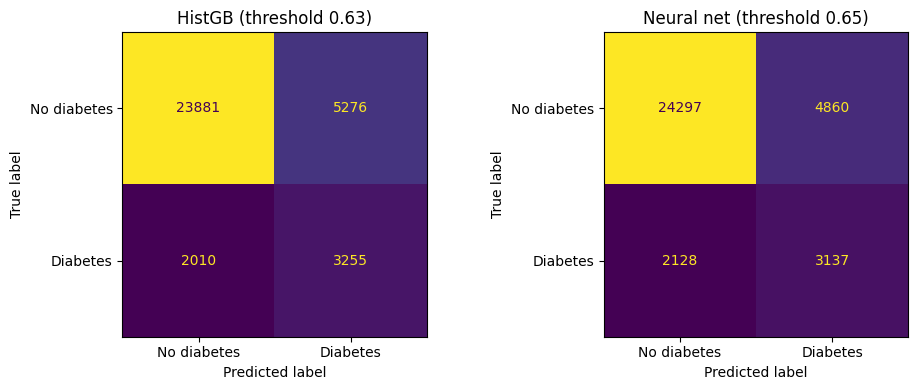

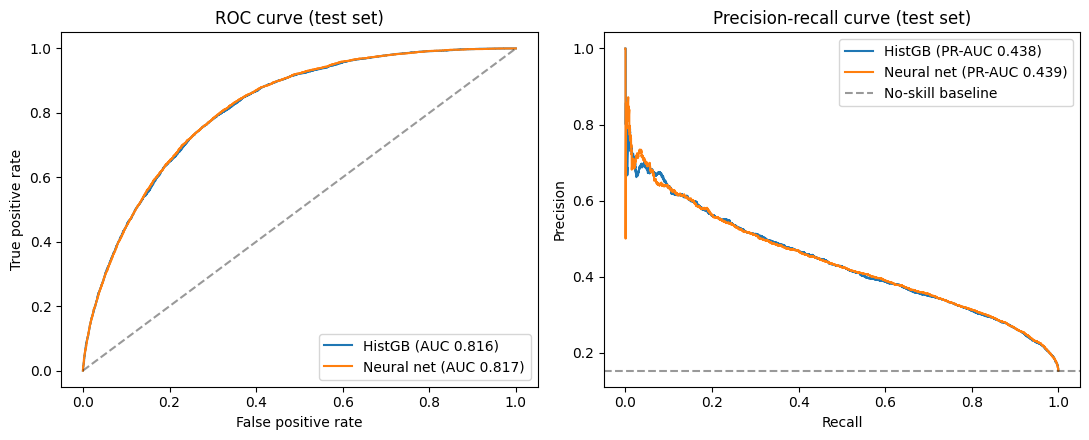

Models saved to: /content/drive/MyDrive/Summative_Diabetes_Project/models


In [14]:
# ---- Experiment 9: threshold tuning on validation, final evaluation on TEST ----
import joblib
from sklearn.metrics import (precision_recall_curve, roc_curve,
                             ConfusionMatrixDisplay, confusion_matrix)

def best_f1_threshold(y_true, prob):
    """Threshold that maximizes F1, chosen on the validation set only."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])

# 1. Validation probabilities (already computed earlier) -> choose thresholds
prob_val_hgb = best_hgb.predict_proba(X_val)[:, 1]
thr_hgb = best_f1_threshold(y_val, prob_val_hgb)
thr_nn = best_f1_threshold(y_val, prob8b)
print(f"Chosen thresholds -> HistGB: {thr_hgb:.3f} | Neural net: {thr_nn:.3f}")

# 2. Test-set probabilities (first time the test set is used)
prob_test_hgb = best_hgb.predict_proba(X_test)[:, 1]
test_ds = make_ds(X_test_fe_s, y_test, training=False)
prob_test_nn = model8b.predict(test_ds, verbose=0).ravel()

# 3. Log both to the experiment table (marked as TEST)
SPLIT_INFO = "70/15/15 stratified, seed 42, evaluated on TEST, threshold tuned on validation"
evaluate_and_log("E9a", "TEST HistGB (E4 model), tuned threshold", "Traditional ML",
                 y_test, prob_test_hgb,
                 {"model": "HistGradientBoosting", **search.best_params_,
                  "threshold_rule": "max F1 on validation"},
                 0.0, threshold=thr_hgb,
                 notes="Final test evaluation; threshold chosen on validation")
table = evaluate_and_log("E9b", "TEST Neural net (E8b model), tuned threshold",
                         "Deep Learning", y_test, prob_test_nn,
                         {"model": "Functional API residual MLP",
                          "features": "21 original + 8 engineered, scaled",
                          "threshold_rule": "max F1 on validation"},
                         0.0, threshold=thr_nn,
                         notes="Final test evaluation; threshold chosen on validation")
display(table.tail(2))

# 4. Compare default 0.5 threshold vs tuned threshold on the test set
rows = []
for name, prob, thr in [("HistGB", prob_test_hgb, thr_hgb),
                        ("Neural net", prob_test_nn, thr_nn)]:
    for label, t in [("0.5 (default)", 0.5), (f"{thr:.2f} (tuned)", thr)]:
        pred = (prob >= t).astype(int)
        rows.append({"model": name, "threshold": label,
                     "precision": round(precision_score(y_test, pred), 3),
                     "recall": round(recall_score(y_test, pred), 3),
                     "f1": round(f1_score(y_test, pred), 3),
                     "accuracy": round(accuracy_score(y_test, pred), 3)})
display(pd.DataFrame(rows))

# 5. Confusion matrices (tuned thresholds)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, prob, thr) in zip(ax, [("HistGB", prob_test_hgb, thr_hgb),
                                     ("Neural net", prob_test_nn, thr_nn)]):
    cm = confusion_matrix(y_test, (prob >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(
        ax=a, colorbar=False, values_format="d")
    a.set_title(f"{name} (threshold {thr:.2f})")
plt.tight_layout()
plt.show()

# 6. ROC and precision-recall curves on the test set
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, prob in [("HistGB", prob_test_hgb), ("Neural net", prob_test_nn)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, prob):.3f})")
    p, r, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(r, p, label=f"{name} (PR-AUC {average_precision_score(y_test, prob):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve (test set)"); ax[0].legend()
ax[1].axhline(y_test.mean(), color="k", ls="--", alpha=0.4, label="No-skill baseline")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curve (test set)"); ax[1].legend()
plt.tight_layout()
plt.show()

# 7. Save the two best models to Drive (for the Drive folder deliverable)
MODEL_DIR = "/content/drive/MyDrive/Summative_Diabetes_Project/models"
os.makedirs(MODEL_DIR, exist_ok=True)
joblib.dump({"model": best_hgb, "threshold": thr_hgb,
             "features": list(X_train.columns)}, f"{MODEL_DIR}/best_traditional_hgb.joblib")
model8b.save(f"{MODEL_DIR}/best_deep_learning_model.h5")
joblib.dump({"scaler": scaler_fe, "threshold": thr_nn,
             "note": "inputs = 21 original + 8 engineered features (see add_features)"},
            f"{MODEL_DIR}/dl_scaler_and_threshold.joblib")
print("Models saved to:", MODEL_DIR)

**What I found:**
- The two models are practically identical on the test set: ROC-AUC 0.816 vs 0.817 and PR-AUC 0.438 vs 0.439. The ROC and PR curves overlap almost completely.
- The tuned thresholds (0.63 and 0.65) are above 0.5 because class weights inflate predicted probabilities.
- Threshold tuning moves me along the same curve: recall falls from about 0.79 to about 0.60 while precision rises from 0.31 to about 0.39.
- The best threshold depends on the use. For screening, missing a case is worse than a false alarm, so the lower threshold (higher recall) is more suitable.

## 8. Error analysis
Here I look at who the gradient boosting model gets wrong on the test set. I compare the average feature values of true positives, false negatives, false positives and true negatives, and I check recall and precision by age band and BMI band.

In [15]:
# ---- Error analysis on the TEST set (HistGB, tuned threshold) ----
pred_hgb = (prob_test_hgb >= thr_hgb).astype(int)
err = X_test.copy()
err["y_true"] = y_test.values
err["pred"] = pred_hgb
err["outcome"] = np.select(
    [(err.y_true == 1) & (err.pred == 1),
     (err.y_true == 1) & (err.pred == 0),
     (err.y_true == 0) & (err.pred == 1)],
    ["TP", "FN", "FP"], default="TN")
print(err["outcome"].value_counts(), "\n")

# 1. Average of key features per outcome group
key = ["HighBP", "HighChol", "GenHlth", "BMI", "Age", "PhysHlth", "DiffWalk", "Income"]
print("Average feature values by outcome:")
print(err.groupby("outcome")[key].mean().round(2), "\n")

# 2. Performance by subgroup
def group_report(g):
    return pd.Series({
        "n": len(g),
        "prevalence": round(g.y_true.mean(), 3),
        "recall": round(recall_score(g.y_true, g.pred), 3),
        "precision": round(precision_score(g.y_true, g.pred, zero_division=0), 3)})

err["age_band"] = pd.cut(err["Age"], bins=[0, 5, 9, 13], labels=["18-44", "45-64", "65+"])
err["bmi_band"] = pd.cut(err["BMI"], bins=[0, 25, 30, 35, 100],
                         labels=["under 25", "25-30", "30-35", "35+"])
for col in ["age_band", "bmi_band"]:
    print(f"Performance by {col}:")
    print(err.groupby(col, observed=True)[["y_true", "pred"]].apply(group_report), "\n")

outcome
TN    23881
FP     5276
TP     3255
FN     2010
Name: count, dtype: int64 

Average feature values by outcome:
         HighBP  HighChol  GenHlth    BMI   Age  PhysHlth  DiffWalk  Income
outcome                                                                    
FN         0.53      0.48     2.67  28.68  8.83      4.18      0.16    5.80
FP         0.87      0.74     3.49  32.53  9.77      9.03      0.42    5.01
TN         0.30      0.33     2.27  26.98  7.48      3.06      0.09    6.22
TP         0.90      0.79     3.68  33.94  9.68     10.25      0.50    4.79 

Performance by age_band:
                n  prevalence  recall  precision
age_band                                        
18-44      7253.0       0.048   0.255      0.353
45-64     14508.0       0.153   0.602      0.393
65+       12661.0       0.213   0.678      0.375 

Performance by bmi_band:
                n  prevalence  recall  precision
bmi_band                                        
under 25  11491.0       0.06

**What I found:**
- Missed cases (false negatives) look like healthy people: lower BMI, better self-rated health and fewer mobility problems.
- False alarms look like true cases: high blood pressure, high cholesterol and high BMI.
- The model can't separate these two groups with the features it has, which keeps precision around 0.38.
- Performance varies by group: recall is 0.84 for BMI 35+ but only 0.25 for BMI under 25, and it is 0.26 for ages 18 to 44 compared with 0.68 for 65+. The model relies heavily on BMI and age.
- Possible reasons: the data is self-reported with no blood tests, and the label means "told by a doctor", so undiagnosed cases look like false alarms. These are explanations I think are plausible, not things I can prove with this data.

## 9. Learning curve (bias-variance check)
I train the tuned gradient boosting model on 10% up to 100% of the training data and compare PR-AUC on the training portion and on validation. This shows whether the model suffers from high variance (a big gap) or whether more data would help.

,train_size,train_PR_AUC,val_PR_AUC
0,16063,0.4901,0.4359
1,40157,0.4539,0.4404
2,80315,0.4570,0.4444
3,120473,0.4485,0.4474
4,160631,0.4478,0.4470


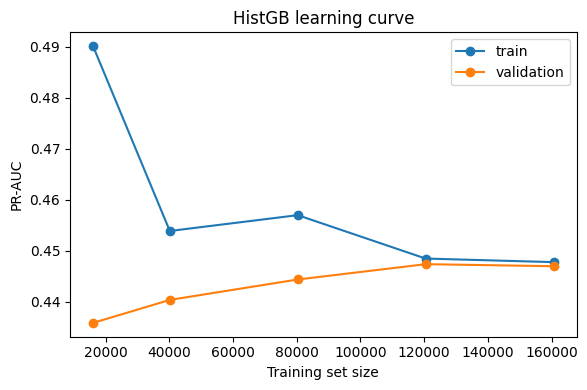

In [16]:
# ---- Learning curve for the classical model (bias-variance diagnosis) ----
fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
rows = []
for f in fractions:
    n = int(len(X_train) * f)
    idx = X_train.sample(n=n, random_state=SEED).index
    m = HistGradientBoostingClassifier(
        max_iter=300, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=15, class_weight="balanced",
        random_state=SEED, **search.best_params_)
    m.fit(X_train.loc[idx], y_train.loc[idx])
    rows.append({
        "train_size": n,
        "train_PR_AUC": average_precision_score(y_train.loc[idx],
                                                m.predict_proba(X_train.loc[idx])[:, 1]),
        "val_PR_AUC": average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
lc = pd.DataFrame(rows).round(4)
display(lc)

plt.figure(figsize=(6, 4))
plt.plot(lc["train_size"], lc["train_PR_AUC"], marker="o", label="train")
plt.plot(lc["train_size"], lc["val_PR_AUC"], marker="o", label="validation")
plt.xlabel("Training set size"); plt.ylabel("PR-AUC")
plt.title("HistGB learning curve"); plt.legend()
plt.tight_layout()
plt.show()

**What I found:** With 16k rows there is a clear gap (train 0.490 vs validation 0.436), which means overfitting. The gap closes as data grows and is almost zero at full size (0.448 vs 0.447). Validation PR-AUC flattens between 120k and 160k rows, so more of the same data wouldn't help. Since a Random Forest and neural networks reach the same ceiling, I think the limit comes from the information in the features, not from model capacity.

## 10. Reproducibility: requirements
This cell writes the exact versions of the libraries I used into `requirements.txt`.

In [17]:
import importlib.metadata as md

pkgs = ["numpy", "pandas", "scikit-learn", "tensorflow", "keras", "matplotlib",
        "seaborn", "wandb", "joblib"]
lines = []
for p in pkgs:
    try:
        lines.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        print("not found:", p)
req_text = "\n".join(lines) + "\n"
print(req_text)

OUT_DIR = "/content/drive/MyDrive/Summative_Diabetes_Project/checkpoints"
os.makedirs(OUT_DIR, exist_ok=True)
with open(f"{OUT_DIR}/requirements.txt", "w") as f:
    f.write(req_text)
print("Saved requirements.txt to", OUT_DIR)

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
tensorflow==2.21.0
keras==3.13.2
matplotlib==3.10.0
seaborn==0.13.2
wandb==0.28.1
joblib==1.6.0

Saved requirements.txt to /content/drive/MyDrive/Summative_Diabetes_Project/checkpoints


In [18]:
import shutil

full_table = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 120)
display(full_table)

CHECKPOINT_DIR = "/content/drive/MyDrive/Summative_Diabetes_Project/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
full_table.to_csv(f"{CHECKPOINT_DIR}/experiment_results.csv", index=False)
shutil.copytree("./wandb_logs", f"{CHECKPOINT_DIR}/wandb_logs", dirs_exist_ok=True)
print("Saved", len(full_table), "experiments and ALL W&B logs to Drive.")

,exp,name,approach,params,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_sec,notes
0,E1,LogReg baseline,Traditional ML,"{'model': 'LogisticRegression', 'C': 1.0, 'class_weight': None, 'max_iter': 1000}",0.500000,0.8532,0.5668,0.1710,0.2627,0.8138,0.4312,0.7,
1,E2,LogReg balanced,Traditional ML,"{'model': 'LogisticRegression', 'C': 1.0, 'class_weight': 'balanced', 'max_iter': 1000}",0.500000,0.7189,0.3233,0.7667,0.4548,0.8141,0.4302,1.6,
2,E3,RandomForest,Traditional ML,"{'model': 'RandomForest', 'n_estimators': 150, 'max_depth': 14, 'min_samples_leaf': 20, 'class_weight': 'balanced_su...",0.500000,0.7309,0.3334,0.7597,0.4634,0.8177,0.4429,48.3,
3,E4,HistGB tuned,Traditional ML,"{'model': 'HistGradientBoosting', 'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_depth': 5, 'learning_rate': 0.0...",0.500000,0.7091,0.3189,0.7945,0.4551,0.8196,0.4467,190.5,
4,E5,HistGB + engineered features,Traditional ML,"{'model': 'HistGradientBoosting', 'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_depth': 5, 'learning_rate': 0.0...",0.500000,0.7098,0.3192,0.7922,0.4550,0.8200,0.4460,11.9,Same settings as E4; only the feature set changed
5,E6,MLP baseline,Deep Learning,"{'model': 'Sequential MLP', 'layers': '64-32-1', 'activation': 'relu', 'optimizer': 'Adam', 'lr': 0.001, 'batch_size...",0.500000,0.8550,0.5954,0.1619,0.2545,0.8192,0.4439,17.0,
6,E7,MLP wide + reg + class weights,Deep Learning,"{'model': 'Sequential MLP', 'layers': '128-64-32-1', 'regularization': 'BatchNorm, Dropout 0.3, L2 1e-4', 'optimizer...",0.500000,0.6982,0.3127,0.8127,0.4516,0.8195,0.4447,77.8,"Loss is class-weighted, so not comparable with E6 loss"
7,E8,Functional resid + LR schedule,Deep Learning,"{'model': 'Functional API, residual block', 'layers': '128 + res128 + 32', 'regularization': 'BatchNorm, Dropout 0.3...",0.500000,0.7012,0.3145,0.8081,0.4527,0.8192,0.4443,75.5,Same features as E7; new architecture and LR schedule
8,E8b,Functional resid + engineered,Deep Learning,"{'model': 'Functional API, residual block', 'layers': '128 + res128 + 32', 'regularization': 'BatchNorm, Dropout 0.3...",0.500000,0.7037,0.3159,0.8041,0.4536,0.8194,0.4460,103.2,Same as E8; only the feature set changed
9,E9a,"TEST HistGB (E4 model), tuned threshold",Traditional ML,"{'model': 'HistGradientBoosting', 'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_depth': 5, 'learning_rate': 0.0...",0.630524,0.7883,0.3815,0.6182,0.4719,0.8159,0.4377,0.0,Final test evaluation; threshold chosen on validation


Saved 11 experiments and ALL W&B logs to Drive.


## 11. Conclusion, limitations and future work
**Summary.** I ran 9 experiments (plus one variant) across logistic regression, random forest, gradient boosting and neural networks. All of them reached about the same ranking quality (ROC-AUC 0.81 to 0.82, PR-AUC 0.43 to 0.45). Gradient boosting and the neural network were equivalent on the test set (PR-AUC about 0.44), but gradient boosting trains faster.

**Limitations.** The data is self-reported survey data from one year (2015), has no lab values, and is imbalanced. The model misses many young and low-BMI people with diabetes.

**Future work.** Add clinical features (blood glucose, HbA1c), try group-specific thresholds, check fairness across age and BMI groups, and test newer data.